In [251]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [252]:
# load the dataset 
df=pd.read_csv(r"D:\chrome downloads\Bank Customer Churn Prediction.csv")

In [253]:
df.head()

,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [254]:
# find duplicates rows and delete it

df.duplicated().sum()
df.drop_duplicates()

,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...
9995,15606229,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,15569892,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,15584532,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,15682355,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


In [255]:
df.shape

(10000, 12)

In [256]:
df.size

120000

In [257]:
df.ndim

2

In [258]:
# find data types

df.dtypes

customer_id           int64
credit_score          int64
country                 str
gender                  str
age                   int64
tenure                int64
balance             float64
products_number       int64
credit_card           int64
active_member         int64
estimated_salary    float64
churn                 int64
dtype: object

In [259]:
# find information

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customer_id       10000 non-null  int64  
 1   credit_score      10000 non-null  int64  
 2   country           10000 non-null  str    
 3   gender            10000 non-null  str    
 4   age               10000 non-null  int64  
 5   tenure            10000 non-null  int64  
 6   balance           10000 non-null  float64
 7   products_number   10000 non-null  int64  
 8   credit_card       10000 non-null  int64  
 9   active_member     10000 non-null  int64  
 10  estimated_salary  10000 non-null  float64
 11  churn             10000 non-null  int64  
dtypes: float64(2), int64(8), str(2)
memory usage: 1.0 MB


In [260]:
# find null values in data set
# there is no null values there

df.isna().sum()

customer_id         0
credit_score        0
country             0
gender              0
age                 0
tenure              0
balance             0
products_number     0
credit_card         0
active_member       0
estimated_salary    0
churn               0
dtype: int64

In [261]:
# convert all column name capital letter to small letter
# replace space to underscore
df.columns=df.columns.str.lower()
df.columns=df.columns.str.replace(" ","_")

In [262]:
# make a age group column based on age
labels=["young_adult","adult","middle_age","senior"]
df["age_group"]=pd.qcut(df["age"],q=4,labels=labels)

In [263]:
for col in ["country","gender","age_group"]:
    df[col]=df[col].str.lower()

In [264]:
df.head()

,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn,age_group
0,15634602,619,france,female,42,2,0.00,1,1,1,101348.88,1,middle_age
1,15647311,608,spain,female,41,1,83807.86,1,0,1,112542.58,0,middle_age
2,15619304,502,france,female,42,8,159660.80,3,1,0,113931.57,1,middle_age
3,15701354,699,france,female,39,1,0.00,2,0,0,93826.63,0,middle_age
4,15737888,850,spain,female,43,2,125510.82,1,1,1,79084.10,0,middle_age


In [265]:
# change column name tenure to years of service
df.rename(columns={"tenure":"years_of_service"},inplace=True)

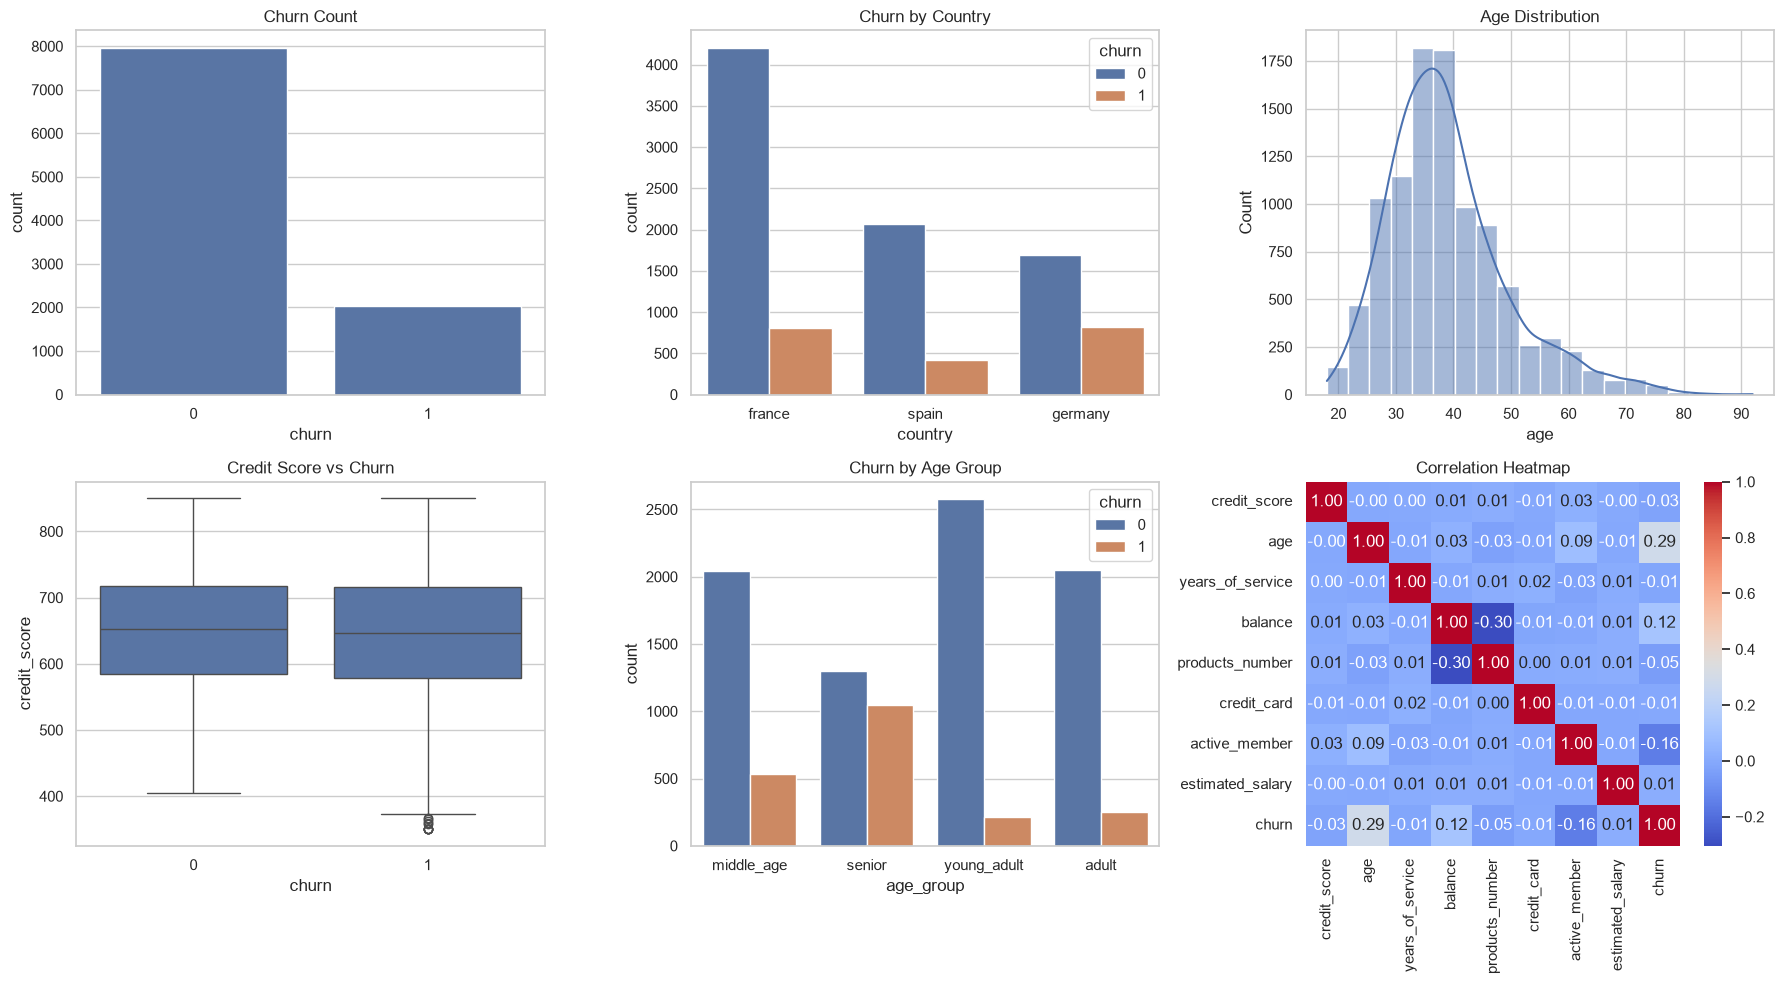

In [266]:
# draw 6 charts based on Overall churn,count Churn rate by country,
# Churn rate by age group,Balance vs churn,Products number vs churn,Correlation heatmap

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. Churn count
sns.countplot(x='churn', data=df, ax=axes[0, 0])
axes[0, 0].set_title('Churn Count')

# 2. Churn by country
sns.countplot(x='country', hue='churn', data=df, ax=axes[0, 1])
axes[0, 1].set_title('Churn by Country')

# 3. Age distribution
sns.histplot(df['age'], bins=20, kde=True, ax=axes[0, 2])
axes[0, 2].set_title('Age Distribution')

# 4. Credit score by churn
sns.boxplot(x='churn', y='credit_score', data=df, ax=axes[1, 0])
axes[1, 0].set_title('Credit Score vs Churn')

# 5. Churn by age group
sns.countplot(x='age_group', hue='churn', data=df, ax=axes[1, 1])
axes[1, 1].set_title('Churn by Age Group')

# 6. Correlation heatmap
sns.heatmap(df.select_dtypes('number').drop(columns='customer_id').corr(),
            annot=True, fmt='.2f', cmap='coolwarm', ax=axes[1, 2])
axes[1, 2].set_title('Correlation Heatmap')

plt.tight_layout()
plt.show()

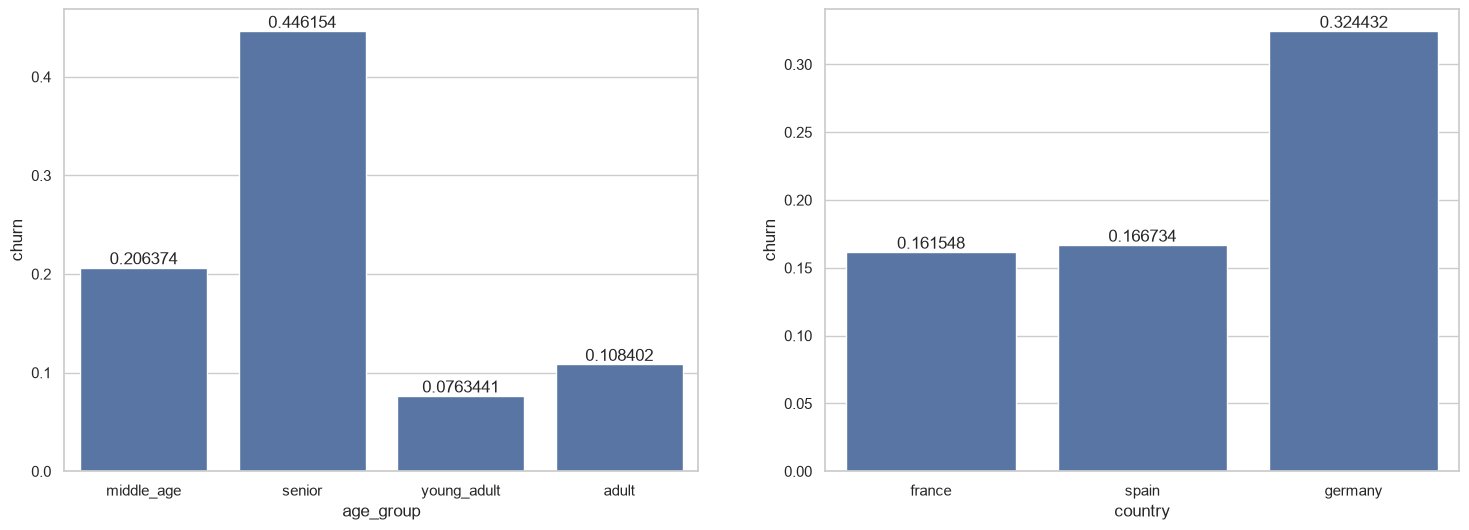

In [267]:
# find count of churn based on country

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(18, 6))


df1=sns.barplot(data=df,x="age_group",y="churn",errorbar=None,ax=axes[0])
for v1 in df1.containers:
    df1.bar_label(v1)

df1=sns.barplot(data=df,x="country",y="churn",errorbar=None, ax=axes[1])
for v1 in df1.containers:
    df1.bar_label(v1)

In [268]:
df=df.drop(columns=["customer_id","age"])

In [269]:
df.head()

,credit_score,country,gender,years_of_service,balance,products_number,credit_card,active_member,estimated_salary,churn,age_group
0,619,france,female,2,0.00,1,1,1,101348.88,1,middle_age
1,608,spain,female,1,83807.86,1,0,1,112542.58,0,middle_age
2,502,france,female,8,159660.80,3,1,0,113931.57,1,middle_age
3,699,france,female,1,0.00,2,0,0,93826.63,0,middle_age
4,850,spain,female,2,125510.82,1,1,1,79084.10,0,middle_age


In [270]:
df["country"].value_counts()

country
france     5014
germany    2509
spain      2477
Name: count, dtype: int64

In [271]:
df["country"]=df["country"].replace({"france":1,"germany":2,"spain":3})
df["gender"]=df["gender"].replace({"male":1,"female":2})
df["age_group"]=df["age_group"].replace({"young_adult":1,"middle_age":2,"senior":3,"adult":4})

In [272]:
df.head()

,credit_score,country,gender,years_of_service,balance,products_number,credit_card,active_member,estimated_salary,churn,age_group
0,619,1,2,2,0.00,1,1,1,101348.88,1,2
1,608,3,2,1,83807.86,1,0,1,112542.58,0,2
2,502,1,2,8,159660.80,3,1,0,113931.57,1,2
3,699,1,2,1,0.00,2,0,0,93826.63,0,2
4,850,3,2,2,125510.82,1,1,1,79084.10,0,2


In [273]:
df["years_of_service"].value_counts()

years_of_service
2     1048
1     1035
7     1028
8     1025
5     1012
3     1009
4      989
9      984
6      967
10     490
0      413
Name: count, dtype: int64

In [274]:
from sklearn.preprocessing import MinMaxScaler

scaler_column=["balance","estimated_salary"]
scaler=MinMaxScaler()

df[scaler_column]=scaler.fit_transform(df[scaler_column])

In [275]:
df.dtypes

credit_score          int64
country              object
gender               object
years_of_service      int64
balance             float64
products_number       int64
credit_card           int64
active_member         int64
estimated_salary    float64
churn                 int64
age_group            object
dtype: object

In [276]:
df["age_group"]=pd.to_numeric(df["age_group"])
df["country"]=pd.to_numeric(df["country"])
df["gender"]=pd.to_numeric(df["gender"])

In [277]:
df.dtypes

credit_score          int64
country               int64
gender                int64
years_of_service      int64
balance             float64
products_number       int64
credit_card           int64
active_member         int64
estimated_salary    float64
churn                 int64
age_group             int64
dtype: object

In [278]:
x=df.drop("churn",axis="columns")
y=df["churn"]

In [279]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=5)

In [280]:
x_train.shape,x_test.shape

((8000, 10), (2000, 10))

In [281]:
x_train.shape

(8000, 10)

In [282]:
y_train.head()

7751    0
4154    0
3881    0
9238    0
5210    0
Name: churn, dtype: int64

In [283]:
import tensorflow as tf
from tensorflow import keras

model=keras.Sequential([keras.layers.Dense(10,input_shape=(x_train.shape[1],),activation="relu"),
                       keras.layers.Dense(1,activation="sigmoid"),])
model.compile(optimizer="adam",loss="binary_crossentropy",metrics=["accuracy"])
model.fit(x_train,y_train,epochs=50)

Epoch 1/50


C:\Users\MOHAMMED RIZWAN\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7755 - loss: 5.2998
Epoch 2/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7874 - loss: 0.5109
Epoch 3/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7871 - loss: 0.5058
Epoch 4/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7878 - loss: 0.5133
Epoch 5/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7931 - loss: 0.4975
Epoch 6/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7859 - loss: 0.5115
Epoch 7/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7905 - loss: 0.4951
Epoch 8/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7880 - loss: 0.5027
Epoch 9/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7879 - loss: 0.5011
Epoch 10/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7895 - loss: 0.4999
Epoch 11/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7878 - loss: 0.5023
Epoch 12/50
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy

In [310]:
model.evaluate(x_test,y_test)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7980 - loss: 0.4960


[0.496019184589386, 0.7979999780654907]

In [311]:
yp = model.predict(x_test)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  


In [312]:
y_test[:5]

7054    0
442     0
3954    0
2288    0
3196    0
Name: churn, dtype: int64

In [338]:
y_pred=[]
for element in yp:
    if element>0.4:
        y_pred.append(1)
    else:
        y_pred.append(0)

In [339]:
y_pred[:10]

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

In [340]:
from sklearn.metrics import confusion_matrix,classification_report
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.80      0.99      0.89      1595
           1       0.35      0.01      0.03       405

    accuracy                           0.80      2000
   macro avg       0.58      0.50      0.46      2000
weighted avg       0.71      0.80      0.71      2000



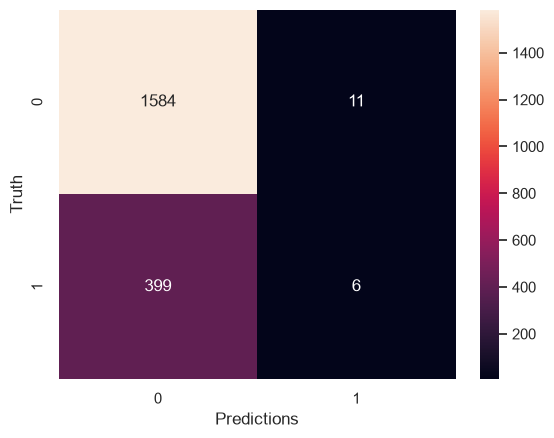

In [341]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d")
plt.xlabel("Predictions")
plt.ylabel("Truth")
plt.show()

In [342]:
predicted_data = x_test.copy()
predicted_data["actual_churn"] = y_test
predicted_data["predicted_churn"] = y_pred
predicted_data["churn_probability"] = yp.ravel()
predicted_data.tail(10)

,credit_score,country,gender,years_of_service,balance,products_number,credit_card,active_member,estimated_salary,age_group,actual_churn,predicted_churn,churn_probability
4321,651,1,1,4,0.364941,1,1,1,0.619772,4,0,0,0.112551
2612,550,3,1,3,0.000000,2,0,0,0.656411,4,0,0,0.215120
6723,699,2,2,2,0.367664,2,0,1,0.456716,3,0,0,0.115691
4327,678,2,2,1,0.556708,2,0,1,0.080680,1,0,0,0.097984
9781,641,1,2,3,0.587256,1,1,1,0.787310,3,1,0,0.171483
6133,667,2,2,4,0.506487,2,1,0,0.345033,4,0,0,0.303916
532,729,1,1,6,0.373436,1,1,1,0.399576,1,0,0,0.047293
1370,769,1,2,7,0.000000,2,1,0,0.884244,1,0,0,0.080500
6514,563,3,1,7,0.000000,2,0,0,0.030644,1,0,0,0.107283
3081,693,1,1,2,0.603244,1,0,0,0.985766,1,0,0,0.164237


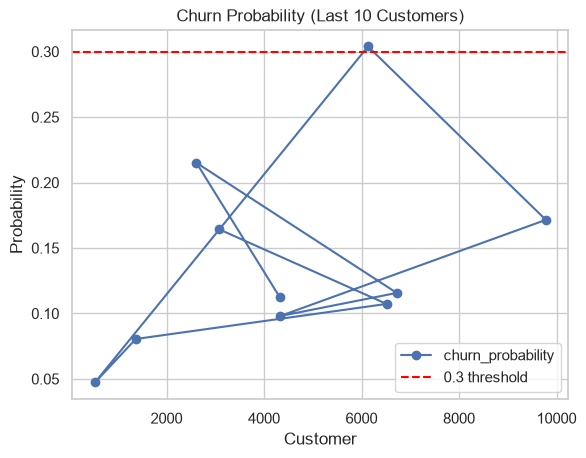

In [346]:
predicted_data["churn_probability"].tail(10).plot(kind="line", marker="o")
plt.axhline(0.3, color="red", linestyle="--", label="0.3 threshold")
plt.title("Churn Probability (Last 10 Customers)")
plt.xlabel("Customer")
plt.ylabel("Probability")
plt.legend()
plt.show()